# Projet Leyenda - Livrable 1
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

# Importation des librairies

In [1]:
%pip install -r requirements.txt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import plotly.express as px
from DL_dataset import *
from plotly.subplots import make_subplots
import plotly.graph_objects as go

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Téléchargement du dataset

In [2]:
folder_raw = Path(f"./data")

if not os.path.exists(folder_raw):
    step_DL, step_unzip = True, True
    os.makedirs(folder_raw)
elif Path(folder_raw).exists() and len(os.listdir(folder_raw)) == 0:
    step_DL, step_unzip = True, True
else:
    step_DL, step_unzip = False, False

urls=[
    "https://drive.google.com/file/d/1Cp-x-Sc7wUzipu1GysZXx9g4Y2jrpIka/view?usp=sharing",
]

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

## Code de chargement du fichier

In [30]:
BATCH_SIZE = 32
IMG_SIZE = (128,128) # Il me semble que c'était le meilleur modele à 64px
img_size = 64
train_split = 0.8
test_split = 0.2 # Ici je fais 0.8 et 0.2 car on a pas bcp de données.

In [31]:
dataset_raw = Path(f"./data/dataset/")
import tensorflow as tf

train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)

AUTOTUNE = tf.data.experimental.AUTOTUNE

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_set = train_set.map(
    lambda x: (normalization_layer(x), normalization_layer(x))
)

test_set = test_set.map(
    lambda x: (normalization_layer(x), normalization_layer(x))
)

train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


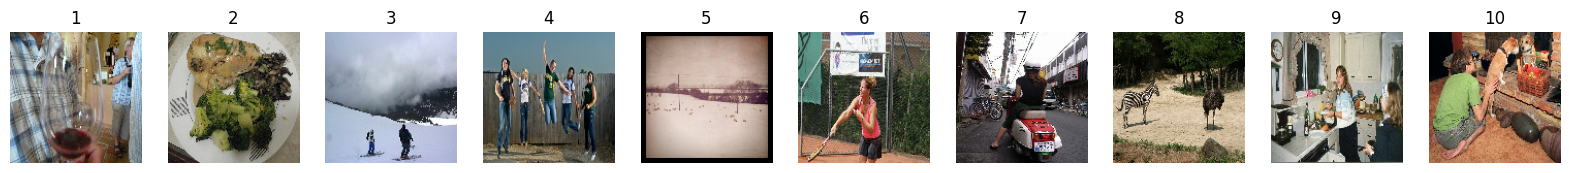

In [32]:
n = 10

plt.figure(figsize=(20, 4))

for images, _ in train_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off")

In [36]:
from tensorflow.keras import layers, Model
def DAE(img_size):
    input_img=layers.Input(shape=(img_size,img_size,3))
    img = layers.GaussianNoise(0.2)(input_img)#ajouter du bruit
    #Encoder
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(img)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x_end = layers.MaxPooling2D((2,2))(x)

    #hidden layer

    #Decoder
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x_end)
    x = layers.Conv2DTranspose(128,(3, 3),strides=(2, 2), padding='same')(x)
    x = layers.Conv2DTranspose(64,(3, 3),strides=(2, 2), padding='same')(x)
    x_decoder = layers.Conv2D(3, (3, 3),activation="sigmoid",  padding='same')(x)

    autoencoder = Model(inputs=input_img, outputs=x_decoder)

    return autoencoder

model = DAE(128) # Pour des images 64x64
model.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_12               │ (None, 128, 128, 3)    │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_12             │ (None, 64, 64, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_13             │ (None, 128, 128, 64)   │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 128, 128, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 446,339 (1.70 MB)

 Trainable params: 446,339 (1.70 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
model.compile(
    optimizer='adam', 
    loss=['mse','BinaryCrossentropy'] # Mean Squared Error (calcule l'écart pixel par pixel)
)

EPOCHS = 20 

history = model.fit(
    train_set,
    validation_data=test_set,
    epochs=EPOCHS
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 817ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0768 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0727
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 502ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0587 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0974
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 476ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0385 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0541
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 476ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0366 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0754
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 499ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0326 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0644
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 454ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0287 - val_conv2d_37_loss: 0.0000e+00 - val_loss: 0.0613
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 452ms/step - conv2d_37_loss: 0.0000e+00 - loss: 0.0271 - val_conv2d_37_loss: 0.0000e+

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


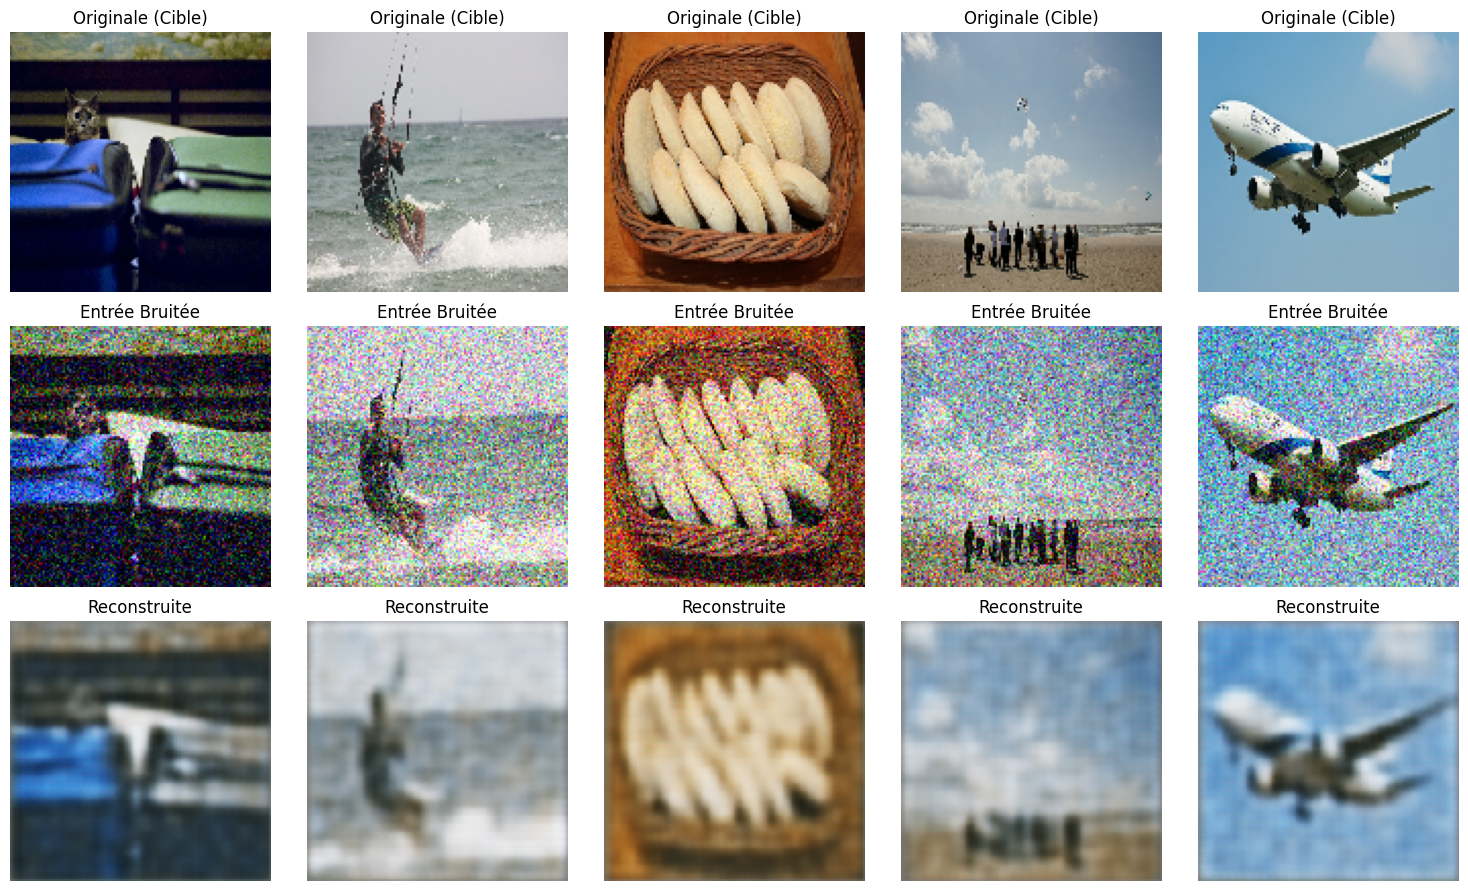

In [40]:

import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Extraire un seul batch d'images du jeu de test
# (Le dataset retourne le tuple (image_originale, image_originale), on prend juste le premier)
images, _ = next(iter(test_set.take(1)))

# 2. Générer les images bruitées pour la visualisation
# On force training=True pour que le bruit s'applique, et on "clip" pour rester entre 0 et 1
noise_layer = tf.keras.layers.GaussianNoise(0.2)
noisy_images = noise_layer(images, training=True)
noisy_images = tf.clip_by_value(noisy_images, 0., 1.)

# 3. Demander au modèle de reconstruire (nettoyer) les images
# La couche de bruit interne du modèle est inactive ici, 
# donc le réseau reçoit nos noisy_images et tente directement de les débruiter.
reconstructed_images = model.predict(noisy_images)

# 4. Affichage côte à côte
n = 5  # Nombre d'images à comparer
plt.figure(figsize=(15, 9))

for i in range(n):
    # Ligne 1 : Images Originales
    plt.subplot(3, n, i + 1)
    plt.imshow(images[i])
    plt.title("Originale (Cible)")
    plt.axis("off")

    # Ligne 2 : Images Bruitées
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(noisy_images[i])
    plt.title("Entrée Bruitée")
    plt.axis("off")

    # Ligne 3 : Images Reconstruites (Débruitées)
    plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(reconstructed_images[i])
    plt.title("Reconstruite")
    plt.axis("off")

plt.tight_layout()
plt.show()